# LightHit stand-alone: quick start

LightHit returns the expected photoelectrons per optical module (OM) and time bin,
split into direct light (order 0), light scattered once (order 1) and more (order ≥2).

* **Part A** needs only the package: an artificial 48-OM array, about a minute.
* **Part B** is Baikal-GVD (clusters 1–5, 1440 OMs) with the data bundle
  `lighthit-bgvd-data`, a few minutes.

The first call of each route compiles its Numba kernels once per installation
(a few minutes); later runs reuse the compiled code.

## 0. Install (once)

```bash
python -m pip install 'lighthit[accelerate]' matplotlib jupyter
lighthit-selftest            # prints "self-test passed"
```

For Part B, unpack the data bundle and point `LIGHTHIT_DATA` to it
(or edit the path in the next cell):

```bash
export LIGHTHIT_DATA=/path/to/lighthit-bgvd-data
```

In [1]:
import os
from dataclasses import replace
from pathlib import Path
import time

import numpy as np
import matplotlib.pyplot as plt
import lighthit as lh

print("LightHit", lh.__version__)
DATA = Path(os.environ.get("LIGHTHIT_DATA", "lighthit-bgvd-data")).expanduser()
OUT = Path("lighthit-demo-output")
OUT.mkdir(exist_ok=True)

def viewer(name, response, source, label):
    """Write OUT/<name>-viewer.html (offline 3D viewer) showing the response and its sources."""
    payload = lh.viewer_payload(response, source=source, event_id=name, label=label)
    return lh.write_event_viewer(payload, OUT / f"{name}-viewer.html").name

print("data bundle found:", (DATA / "tables" / "muon-data.json").is_file())

LightHit 0.3.0a3
data bundle found: True


## Part A. Artificial detector, no data

### A1. Medium, detector, kernel and tables

A `TransportKernel` holds the medium, the detector and the numerical settings.
`kernel.build` prepares the radiative-transfer tables once; every later event reuses them.

In [2]:
from lighthit.examples.synthetic import synthetic_medium_model, baikal_like_detector
from lighthit.shower import ShowerData, ShowerTransport
from lighthit.event import EventTransport, SourceComponent

medium = synthetic_medium_model()            # artificial Baikal-like water
detector = baikal_like_detector(clusters=1)  # 8 strings x 6 OMs, artificial
config = lh.KernelConfig(
    omega_per_ns=np.linspace(0.0, 1.2, 65),               # RTE frequencies
    readout_omega_per_ns=np.linspace(0.0, 1.2, 321),      # readout grid
    relative_time_edges_ns=np.arange(-60.0, 745.0, 5.0),  # 5 ns bins
    wavelength_nodes=3, scattering_degree=8, source_degree=8, azimuthal_degree=2,
    radial_range_m=(2.0, 150.0), radial_nodes=48,
    k_max_per_m=4.0, k_panel_per_m=0.1, k_order=6,
    threshold_pe=0.01, cache_directory=str(OUT / "demo-cache"), cache_policy="build")
kernel = lh.TransportKernel(medium, detector, config)

centre = lh.describe_geometry(detector).centroid_m
def shower_at(offset, direction, seed):
    pose = lh.SourcePose(centre + np.asarray(offset, float), direction)
    shower = lh.SyntheticShower.gaussian(pose, charged_track_length_m=300.0,
                                         elements=2000, seed=seed)
    return replace(shower.elements, cone_model="spectral")   # per-wavelength cone

first = shower_at([-12.0, 8.0, 0.0], [0.35, -0.15, 0.925], seed=7)
second = shower_at([20.0, -15.0, 30.0], [-0.30, 0.20, 0.93], seed=8)

start = time.time()
kernel.build(source=first)                                   # RTE tables
kernel.ge2_kernel_store().save(OUT / "demo-cache" / "ge2-pack")  # order >=2 kernels
data = ShowerData.of(OUT / "demo-cache", OUT / "demo-cache" / "ge2-pack")
print(f"tables ready in {time.time() - start:.0f} s")

tables ready in 1 s


### A2. One shower

In [3]:
response = ShowerTransport(kernel, data)(first)
print("route:", response.metadata["route"])
print("active OMs:", int(response.active.sum()), "of", response.charge_pe.size)
print("pe in orders 0, 1, >=2:", response.charge_components_pe.sum(axis=0).round(2))
viewer("synthetic-shower", response, first, "synthetic shower")

route: lighthit.shower
active OMs: 34 of 48
pe in orders 0, 1, >=2: [66.49 50.68 22.5 ]


'synthetic-shower-viewer.html'

### A3. Two showers in one event

All sources share one clock per OM, and OMs are selected on the summed charge.

In [4]:
event = EventTransport(kernel, shower_data=data)
pair = [SourceComponent("shower", first, label="A"), SourceComponent("shower", second, label="B")]
both = event(pair)
print("active OMs:", int(both.active.sum()))
for part in both.metadata["event_components"]:
    print(f"  source {part['label']}: {part['charge_pe']:.2f} pe")
viewer("two-showers", both, pair, "two synthetic showers")

active OMs: 33
  source A: 139.68 pe
  source B: 135.55 pe


'two-showers-viewer.html'

### A4. Calibration laser (isotropic flash, one wavelength)

In [5]:
flash = lh.IsotropicFlash.monochromatic(centre + [0.0, 0.0, 30.0], 1e10, 450.0)
kernel.build(source=flash)          # its own monochromatic table, once
laser = EventTransport(kernel, laser_kernel=kernel)(flash)
print("active OMs:", int(laser.active.sum()), " total:", round(float(laser.charge_pe.sum()), 1), "pe")
viewer("synthetic-laser", laser, flash, "450 nm flash")

active OMs: 48  total: 153762.2 pe


'synthetic-laser-viewer.html'

## Part B. Baikal-GVD with the data bundle

| Bundle path | Content |
|---|---|
| `model/bgvd-model.npz` | water, OM response and geometry of clusters 1–5, as in NTSim |
| `tables/rte-cache/` | radiative-transfer tables (65 frequencies, 9 wavelengths) |
| `tables/ge2-pack/` | order ≥2 kernels |
| `tables/muon/` | muon atlases |
| `tables/laser-cache/` | 532 nm laser table |
| `tables/muon-data.json` | manifest: the routes find all tables next to `rte-cache` |
| `events/` | inputs: Geant4 100 GeV electron; 1 TeV muon steps and their family table |
| `bgvd-model/` | BGVD water/OM package needed by NTSim (not by this notebook) |

### B1. Model and kernel

`lh.load_model` reads the stored model without the `bgvd-model` package. Tables are
found by the physics (water, OM response, settings), not by labels, so a model from
`lh.load_bgvd_model` or NTSim finds them too; `cache_policy="require"` never rebuilds them.

In [6]:
model = lh.load_model(DATA / "model" / "bgvd-model.npz")
kernel = model.kernel(lh.KernelConfig(
    omega_per_ns=np.linspace(0.0, 1.2, 65),
    readout_omega_per_ns=np.linspace(0.0, 1.2, 321),
    relative_time_edges_ns=np.arange(-60.0, 745.0, 5.0),
    cache_directory=DATA / "tables" / "rte-cache", cache_policy="require"))
print(model.detector.positions_m.shape[0], "OMs")

1440 OMs


### B2. A shower from Geant4

`G4Shower.from_hdf5` reads the charged steps of a stored Geant4 event; `placed`
moves its light centroid and axis to a chosen vertex and direction.

In [7]:
from lighthit.shower import ShowerTransport

phase_max = float(np.max(kernel.medium.sample(kernel.wavelength.wavelength_nm)["phase_index"]))
g4 = lh.G4Shower.from_hdf5(DATA / "events" / "geant4-electron-100GeV.h5", event=5,
                           reference_phase_index=phase_max)
electron = replace(g4.elements, cone_model="spectral").placed(
    lh.SourcePose(position_m=[5.0, -269.5, 330.0], direction=[0.35, -0.20, 0.915]))

start = time.time()
shower = ShowerTransport(kernel)        # tables from muon-data.json next to the cache
response = shower(electron)
print(f"{response.metadata['route']}: {int(response.active.sum())} active OMs, "
      f"pe in orders 0, 1, >=2 = {response.charge_components_pe.sum(axis=0).round(2)}, "
      f"{time.time() - start:.1f} s")

lighthit.shower: 28 active OMs, pe in orders 0, 1, >=2 = [2.64 1.9  1.05], 18.1 s


### B3. Where to look: charge and waveforms

`charge_pe` is per OM over all times; `components_pe[om, bin, order]` holds the
binned signal of each order. Bins are relative to `time_origin_ns[om]`.

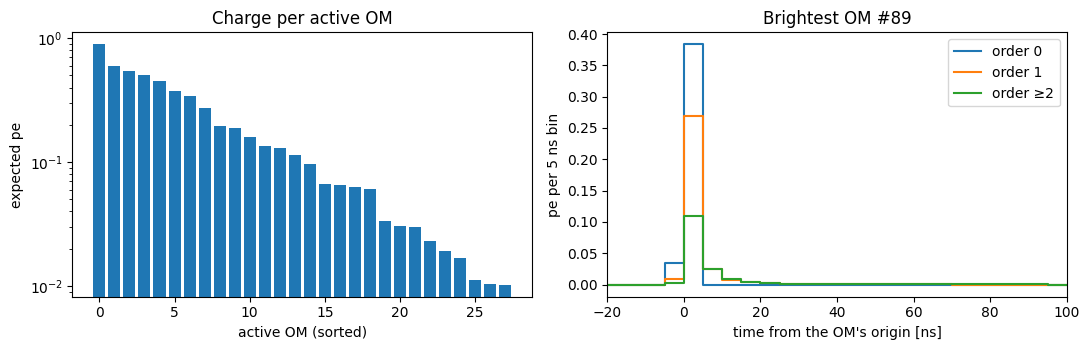

OM 89: 0.892 pe, origin 224.8 ns
OM 269: 0.598 pe, origin 179.8 ns
OM 268: 0.542 pe, origin 131.4 ns


In [8]:
edges = np.asarray(kernel.config.relative_time_edges_ns)
centres = 0.5 * (edges[1:] + edges[:-1])
active = np.flatnonzero(response.active)
best = active[np.argsort(response.charge_pe[active])[::-1][:3]]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(range(len(active)), np.sort(response.charge_pe[active])[::-1])
axes[0].set(xlabel="active OM (sorted)", ylabel="expected pe", yscale="log",
            title="Charge per active OM")
om = best[0]
for order, label in enumerate(("order 0", "order 1", "order ≥2")):
    axes[1].step(centres, response.components_pe[om, :, order], where="mid", label=label)
axes[1].set(xlim=(-20, 100), xlabel="time from the OM's origin [ns]", ylabel="pe per 5 ns bin",
            title=f"Brightest OM #{om}")
axes[1].legend()
plt.tight_layout()
plt.show()
for i in best:
    print(f"OM {i}: {response.charge_pe[i]:.3f} pe, origin {response.time_origin_ns[i]:.1f} ns")

### B4. A muon with its secondaries

The muon route needs the steps and the family table (which step descends from which
secondary of the muon). NTSim builds both automatically (second notebook).

In [9]:
with np.load(DATA / "events" / "muon-1TeV-steps.npz") as f:
    muon_steps = lh.SpectralLightElements(**{k: f[k] for k in f.files if k != "metadata"},
                                          cone_model="spectral")
with np.load(DATA / "events" / "muon-1TeV-ancestry.npz") as f:
    ancestry = {k: f[k] for k in f.files}

start = time.time()
muon = lh.MuonTransport(kernel)(muon_steps, ancestry, primary_uid=0)
print(f"{muon.metadata['route']}: {int(muon.active.sum())} active OMs, "
      f"pe in orders 0, 1, >=2 = {muon.charge_components_pe.sum(axis=0).round(1)}, "
      f"{time.time() - start:.1f} s")

lighthit.muon: 31 active OMs, pe in orders 0, 1, >=2 = [2.2 1.5 0.8], 39.0 s


### B5. Several sources in one event (e.g. ν_μ CC: muon + vertex shower)

In [10]:
from lighthit.event import EventTransport, SourceComponent

start = time.time()
parts = [SourceComponent("muon", muon_steps, ancestry, primary_uid=0, label="muon"),
         SourceComponent("shower", electron, label="vertex shower")]
combined = EventTransport(kernel)(parts)
print(f"{int(combined.active.sum())} active OMs, {time.time() - start:.1f} s")
for part in combined.metadata["event_components"]:
    print(f"  {part['label']:14s} {part['kind']:7s} {part['charge_pe']:8.2f} pe")

61 active OMs, 93.1 s
  muon           muon        4.41 pe
  vertex shower  shower      5.59 pe


### B6. Calibration laser: 532 nm, 10¹⁵ photons, between clusters 1, 2 and 4

The flash sits at the centre of the three cluster axes, at their mean depth;
the 532 nm table comes from the bundle.

In [11]:
from lighthit.event import laser_kernel

laser_k = laser_kernel(model.medium, model.detector, cache_directory=DATA / "tables" / "laser-cache",
                       bin_ns=5.0, omega_per_ns=np.linspace(0.0, 1.2, 321), cache_policy="require")
centre = [-62.0, -385.0, 361.0]   # between clusters 1, 2 and 4 [m]
flash = lh.IsotropicFlash.monochromatic(centre, 1e15, 532.0)
start = time.time()
laser = EventTransport(kernel, laser_kernel=laser_k)(flash)
print(f"{int(laser.active.sum())} active OMs, {float(laser.charge_pe.sum()):.3g} pe, "
      f"{time.time() - start:.1f} s")

1002 active OMs, 1.99e+07 pe, 0.3 s


### B7. Save and look in the browser

`write_event_viewer` writes one offline HTML file (open it in Chrome, Edge or Safari):
3D scene with glowing OMs and the light front, the Module tab with the waveform of
any OM by order, and the Movie tab for MP4 export. `viewer()` from the first cell
passes the transported sources as `source=` (one object or a list): a muon is drawn as
its track, a shower as an axis growing along its direction, a flash as a point. Part A
wrote its viewers next to each source; here are those of Part B.

In [12]:
combined.save(OUT / "numu-like-event.npz")
viewer("electron", response, electron, "100 GeV electron (Geant4)")
viewer("muon", muon, parts[0], "1 TeV muon")
viewer("numu-like", combined, parts, "1 TeV muon + 100 GeV vertex shower")
viewer("laser-532nm", laser, flash, "532 nm calibration flash")
print(sorted(p.name for p in OUT.glob("*-viewer.html")))

['electron-viewer.html', 'laser-532nm-viewer.html', 'muon-viewer.html', 'numu-like-viewer.html', 'synthetic-laser-viewer.html', 'synthetic-shower-viewer.html', 'two-showers-viewer.html']


## Response at a glance

| Field | Shape | Meaning |
|---|---|---|
| `charge_pe` | (OM,) | expected pe, all times |
| `charge_components_pe` | (OM, 3) | the same by order 0, 1, ≥2 |
| `bins_pe`, `components_pe` | (OM, bin), (OM, bin, 3) | binned signal |
| `time_origin_ns` | (OM,) | absolute time of each OM's bin zero |
| `active` | (OM,) | total charge above threshold |
| `metadata` | dict | route, timings, sources, selection |

Order ≥2 may show small signed ringing; it is never clipped. More: the LightHit README.